<a href="https://colab.research.google.com/github/zhengyangsu/Computer-Vision-Project-Overview/blob/main/ComputerVisionProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center><h1> <b> Object Detection Using YOLO <b> </h1></center>

In [3]:
import os

from google.colab import drive
drive.mount('/content/drive')
try: os.makedirs('/content/drive/MyDrive/Colab_Notebooks')
except Exception as e:
    print("Directory already exist", e)
%cd '/content/drive/MyDrive/Colab_Notebooks'
!ls

ModuleNotFoundError: No module named 'google'

Local Test


In [17]:
'''
# Pick ONE base folder (uncomment the one that matches your computer)
base_dir = r'G:\My Drive\Colab_Notebooks'              # Windows
work_dir = r'G:\My Drive\Colab_Notebooks\workbench'
# base_dir = '/Users/leonsu/Colab_Notebooks'           # Mac

os.chdir(base_dir)
print(os.getcwd())
print(os.listdir(base_dir))

dataset_dir = os.path.join(base_dir, 'Cycling_Hand_Signals_Dataset')
data_dir = dataset_dir
'''

G:\My Drive\Colab_Notebooks
['Cycling_Hand_Signals_Dataset', 'yolov8s.pt', 'config.yaml', 'workbench', 'weights']


Importing required Libraries

In [7]:
from PIL import Image
from tensorflow import keras
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import tensorflow as tf
import cv2
import seaborn as sns
import glob
import xml.etree.ElementTree as ET
import os
import shutil
import pandas as pd

# Dataset Description






# Data  

### Classification:  
0: Caution  
1: Cyclist  
2: Left Turn  
3: Right Turn  
4: Stop

In [ ]:
dataset_dir = '/content/drive/MyDrive/Colab_Notebooks/Cycling_Hand_Signals_Dataset'
url = 'https://github.com/zhengyangsu/Computer-Vision-Project-Overview/releases/download/v1.0/Cycling_Hand_Signals_Dataset.zip'

if os.path.isdir(dataset_dir):
    print(f'Dataset already exists at {dataset_dir}, skipping download.')
else:
    !wget -q {url} -O tmp.zip
    !unzip -q tmp.zip -d {dataset_dir} && rm tmp.zip

!ls {dataset_dir}


Dataset already exists at /content/drive/MyDrive/Colab_Notebooks/Cycling_Hand_Signals_Dataset, skipping download.
data.yaml  Final_data  README.roboflow.txt  test  train  valid


# Data Preprocessing

For preprocessing:
- We have to convert the dataset into that acceptable by YOLO.
  - Heirarchy of folders should be the one accepted by YOLO
  - Labels format should be darknet YOLO.
  - Labels files should be .txt files
- Check and see if there are any missing labels or images. And remove them from dataset.


## Heirarchy of Folders correction

Defining paths to train and test folders.

In [ ]:
data_dir = '/content/drive/MyDrive/Colab_Notebooks/Cycling_Hand_Signals_Dataset'

train_dir = f'{data_dir}/train'
valid_dir = f'{data_dir}/valid'
test_dir  = f'{data_dir}/test'

print(train_dir)
print(valid_dir)
print(test_dir)

/content/drive/MyDrive/Colab_Notebooks/Cycling_Hand_Signals_Dataset/train
/content/drive/MyDrive/Colab_Notebooks/Cycling_Hand_Signals_Dataset/valid
/content/drive/MyDrive/Colab_Notebooks/Cycling_Hand_Signals_Dataset/test




The train and test folders have all the images and labels together.

But for YOLO, the directories should be in:

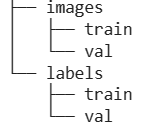


Making directories according to above struture of folders

In [ ]:
#run it once for making directories

base_dir = f'{data_dir}/Final_data'
try: os.makedirs(base_dir)
except Exception as e:
    print("Directory already exist", e)

for kind in ['images', 'labels']:
    for split in ['train', 'valid', 'test']:
        os.makedirs(os.path.join(base_dir, kind, split), exist_ok=True)

Directory already exist [Errno 17] File exists: '/content/drive/MyDrive/Colab_Notebooks/Cycling_Hand_Signals_Dataset/Final_data'


In [ ]:
#set the paths to labels and images directory
# base_dir from existing var
label_dir = os.path.join(base_dir, 'labels')
image_dir = os.path.join(base_dir, 'images')

print(label_dir)
print(image_dir)

/content/drive/MyDrive/Colab_Notebooks/Cycling_Hand_Signals_Dataset/Final_data/labels
/content/drive/MyDrive/Colab_Notebooks/Cycling_Hand_Signals_Dataset/Final_data/images


Copy TXT files and jpg files from the train folder to the folders created.

In [ ]:
final_dir = f'{data_dir}/Final_data'
image_dir = f'{final_dir}/images'
label_dir = f'{final_dir}/labels'

split_names = ['train', 'valid', 'test']

# Names of the subfolders inside each split. Match these to your Drive exactly.
SRC_IMAGE_FOLDER = 'images'     # you wrote "image" (singular); change if it's "images"
SRC_LABEL_FOLDER = 'labels'


def copy_files(src_folder, dst_folder, extensions):
  if os.path.isdir(dst_folder) and os.listdir(dst_folder):
    print(f'  skipped {dst_folder} (already has {len(os.listdir(dst_folder))} files)')
    return 0

  """Copy files with the given extensions from src_folder to dst_folder."""
  os.makedirs(dst_folder, exist_ok=True)
  count = 0
  for file in os.listdir(src_folder):
    if os.path.splitext(file)[1].lower() in extensions:
      shutil.copy(os.path.join(src_folder, file), dst_folder)
      count += 1
  return count


for split in split_names:
    src_images = f'{data_dir}/{split}/{SRC_IMAGE_FOLDER}'
    src_labels = f'{data_dir}/{split}/{SRC_LABEL_FOLDER}'

    n_img = copy_files(src_images, f'{image_dir}/{split}', ('.jpg', '.jpeg', '.png'))
    n_lbl = copy_files(src_labels, f'{label_dir}/{split}', ('.txt',))
    print(f'{split}: copied {n_img} images, {n_lbl} labels')

  skipped /content/drive/MyDrive/Colab_Notebooks/Cycling_Hand_Signals_Dataset/Final_data/images/train (already has 5373 files)
  skipped /content/drive/MyDrive/Colab_Notebooks/Cycling_Hand_Signals_Dataset/Final_data/labels/train (already has 5373 files)
train: copied 0 images, 0 labels
  skipped /content/drive/MyDrive/Colab_Notebooks/Cycling_Hand_Signals_Dataset/Final_data/images/valid (already has 1535 files)
  skipped /content/drive/MyDrive/Colab_Notebooks/Cycling_Hand_Signals_Dataset/Final_data/labels/valid (already has 1535 files)
valid: copied 0 images, 0 labels
  skipped /content/drive/MyDrive/Colab_Notebooks/Cycling_Hand_Signals_Dataset/Final_data/images/test (already has 768 files)
  skipped /content/drive/MyDrive/Colab_Notebooks/Cycling_Hand_Signals_Dataset/Final_data/labels/test (already has 768 files)
test: copied 0 images, 0 labels


Visualizing somme pictures from the dataset

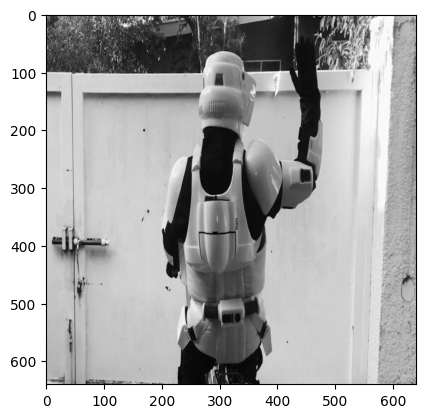

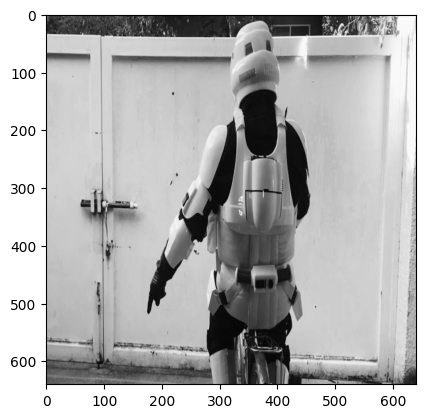

In [ ]:
#visualize first four sample images from train data
for idx, image in enumerate(os.listdir(os.path.join(image_dir, "train"))):
    img = cv2.imread(os.path.join(image_dir,"train", image), 1)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) #color conversion
    plt.imshow(img)
    plt.show()

    if idx == 1:
        break

## Creating Dataframe from txt labels
Creating Dataframes from txt files


In [ ]:
class_names = ['Caution', 'Cyclist', 'Left Turn', 'Right Turn', 'Stop']

rows = []
for split in ['train', 'valid', 'test']:
    label_folder = f'{data_dir}/{split}/labels'
    for file in os.listdir(label_folder):
        if not file.endswith('.txt'):
            continue
        with open(os.path.join(label_folder, file)) as f:
            for line in f:
                parts = line.split()
                if len(parts) < 5:          # skip blank or malformed lines
                    continue
                rows.append({
                    'split': split,
                    'name': os.path.splitext(file)[0],
                    'class': int(parts[0]),
                    'x_center': float(parts[1]),
                    'y_center': float(parts[2]),
                    'box_width': float(parts[3]),
                    'box_height': float(parts[4]),
                })

df = pd.DataFrame(rows)
df['label'] = df['class'].map(dict(enumerate(class_names)))
#display(df.head())
cols = ['split', 'class', 'label', 'x_center', 'y_center', 'box_width', 'box_height', 'name'] #reorder columns
df = df[cols]
display(df.sample(10, random_state=0))
print(df['split'].value_counts())


,split,class,label,x_center,y_center,box_width,box_height,name
7476,train,1,Cyclist,0.401562,0.582812,0.126562,0.530469,4th-vid-mp4_frame982_jpg.rf.e4f66aebac2c2c17f2...
6274,train,1,Cyclist,0.330469,0.473438,0.199219,0.942187,4th-vid-mp4_frame1264_jpg.rf.e36a666d16b66be11...
10004,valid,2,Left Turn,0.613281,0.384375,0.139063,0.093750,4th-vid-mp4_frame355_jpg.rf.518b0d0d005b6e2996...
6608,train,2,Left Turn,0.331250,0.414062,0.315625,0.153125,3rd-edited-mp4_frame495_jpg.rf.8d3b256d7a0fc29...
10250,test,2,Left Turn,0.414062,0.463281,0.122656,0.082031,1st-edited-mp4_frame90_jpg.rf.cbf0bb8184b25abe...
4391,train,1,Cyclist,0.669531,0.532813,0.161719,0.888281,2nd-Edited-mp4_frame2997_jpg.rf.76a17ffa1b49b8...
2876,train,0,Caution,0.373437,0.442969,0.087500,0.067187,2nd-Edited-mp4_frame5476_jpg.rf.d8bfbbdc8dd4ed...
2573,train,0,Caution,0.746094,0.603906,0.132812,0.300781,3rd-edited-mp4_frame4858_jpg.rf.f36dd20ab6758d...
6501,train,0,Caution,0.521875,0.487500,0.107031,0.269531,1st-edited-mp4_frame2133_jpg.rf.057aae76a1ccfc...
9267,valid,0,Caution,0.481250,0.490625,0.097656,0.305469,1st-edited-mp4_frame2146_jpg.rf.a091d216cfd9fb...


split
train    7800
valid    2256
test     1148
Name: count, dtype: int64


Sanity Check

In [ ]:
# Class balance per split
print(df.groupby(['split', 'label']).size().unstack(fill_value=0), end="\n\n")

# Images with no boxes
n_labeled = df.groupby('split')['name'].nunique()
print(n_labeled, end="\n\n")

# Sanity check: bb between 0 and 1
print(df[['x_center', 'y_center', 'box_width', 'box_height']].describe())

label  Caution  Cyclist  Left Turn  Right Turn  Stop
split                                               
test       247      569         86         120   126
train     1674     3808        681         777   860
valid      448     1111        198         252   247

split
test      623
train    4316
valid    1260
Name: name, dtype: int64

           x_center      y_center     box_width    box_height
count  11204.000000  11204.000000  11204.000000  11204.000000
mean       0.483925      0.517520      0.167775      0.488912
std        0.170823      0.115574      0.092325      0.302894
min        0.051562      0.148438      0.010156      0.004687
25%        0.342187      0.448437      0.100000      0.214648
50%        0.457813      0.533594      0.150000      0.435937
75%        0.637500      0.595313      0.210938      0.776563
max        0.953125      0.976562      0.620313      1.000000


In [ ]:
#train_df = df[df['split'] == 'train'].reset_index(drop=True)
train_df = df[df['split'] == 'train']
val_df = df[df['split'] == 'valid']
test_df = df[df['split'] == 'test']

print('Train')
display(train_df.head(5))
print('\n\nVal')
display(val_df.head(5))
print('\n\nTest')
display(test_df.sample(5))



Train


,split,class,label,x_center,y_center,box_width,box_height,name
0,train,1,Cyclist,0.390625,0.634375,0.157812,0.487500,2nd-Edited-mp4_frame1104_jpg.rf.d8ff7b982f4a1f...
1,train,1,Cyclist,0.051562,0.701562,0.103125,0.596875,2nd-Edited-mp4_frame1104_jpg.rf.d8ff7b982f4a1f...
2,train,1,Cyclist,0.334375,0.428125,0.183594,0.728125,2nd-Edited-mp4_frame4164_jpg.rf.ee23e2da58794d...
3,train,2,Left Turn,0.367188,0.275000,0.142969,0.378125,4th-vid-mp4_frame835_jpg.rf.d020d4311e95584be0...
4,train,2,Left Turn,0.813281,0.270313,0.125781,0.384375,4th-vid-mp4_frame835_jpg.rf.d020d4311e95584be0...




Val


,split,class,label,x_center,y_center,box_width,box_height,name
7800,valid,1,Cyclist,0.328125,0.446875,0.161719,0.699219,2nd-Edited-mp4_frame4189_jpg.rf.5d90cee59ccfd1...
7801,valid,1,Cyclist,0.771094,0.532813,0.406250,0.934375,2nd-Edited-mp4_frame6149_jpg.rf.013fd67d2d978b...
7802,valid,1,Cyclist,0.440625,0.574219,0.211719,0.851562,2nd-Edited-mp4_frame6149_jpg.rf.013fd67d2d978b...
7803,valid,0,Caution,0.696094,0.510938,0.175000,0.350000,3rd-edited-mp4_frame2263_jpg.rf.3deb6a7fc4d9cb...
7804,valid,0,Caution,0.710938,0.522656,0.206250,0.472656,3rd-edited-mp4_frame4986_jpg.rf.171eeb6f29a903...




Test


,split,class,label,x_center,y_center,box_width,box_height,name
10192,test,2,Left Turn,0.578125,0.392969,0.142187,0.144531,4th-vid-mp4_frame324_jpg.rf.92c42653f48c5a44fc...
10470,test,1,Cyclist,0.598437,0.535156,0.233594,0.928906,2nd-Edited-mp4_frame753_jpg.rf.56747626d6fe912...
10807,test,4,Stop,0.220312,0.317188,0.082812,0.409375,4th-vid-mp4_frame1229_jpg.rf.5d59d3ff78367eaa7...
11184,test,1,Cyclist,0.701562,0.530469,0.155469,0.939063,4th-vid-mp4_frame1185_jpg.rf.9c17ad121ff5d1353...
10436,test,0,Caution,0.290625,0.612500,0.152344,0.378125,3rd-edited-mp4_frame4531_jpg.rf.dfe13ed60cdce7...


Visualizing one of the image in train set with the bounding box

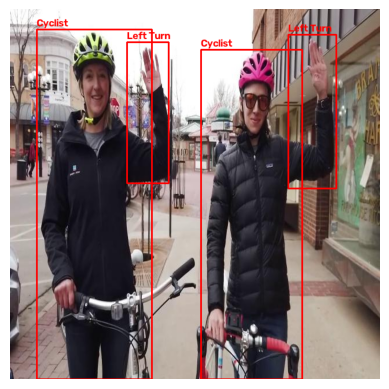

In [ ]:
index = 13
name = train_df.loc[index, 'name']

img = cv2.imread(f'{data_dir}/train/images/{name}.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)            # fix the blue-tint color order
h, w = img.shape[:2]

# All box for this image (an image can have several rows, cyclist plus hand signal)
for _, row in train_df[train_df['name'] == name].iterrows():
    x1 = int((row['x_center'] - row['box_width']  / 2) * w) #multiple as yolo label store coordinate as fraction
    y1 = int((row['y_center'] - row['box_height'] / 2) * h)
    x2 = int((row['x_center'] + row['box_width']  / 2) * w)
    y2 = int((row['y_center'] + row['box_height'] / 2) * h)

    cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
    cv2.putText(img, str(row['label']), (x1, max(y1 - 5, 15)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)

plt.imshow(img)
plt.axis('off')
plt.show()

#display(train_df.loc[10:18, ['name', 'label', 'x_center', 'y_center', 'box_width', 'box_height']])
#print(train_df.loc[10:18, 'name'].nunique(), "different image name(s)")

Checking to see if the above image has bounding boxes around other cylist/hand gesture or not.

In [ ]:
train_df["name"][index]
filtered_df = train_df[train_df['name'] == train_df["name"][index]]
print(filtered_df)

    split  class      label  x_center  y_center  box_width  box_height  \
10  train      2  Left Turn  0.817187  0.277344   0.128125    0.415625   
11  train      2  Left Turn  0.371875  0.280469   0.112500    0.380469   
12  train      1    Cyclist  0.653125  0.554688   0.274219    0.890625   
13  train      1    Cyclist  0.228125  0.527344   0.309375    0.945312   

                                                 name  
10  4th-vid-mp4_frame839_jpg.rf.5be29142e82df54065...  
11  4th-vid-mp4_frame839_jpg.rf.5be29142e82df54065...  
12  4th-vid-mp4_frame839_jpg.rf.5be29142e82df54065...  
13  4th-vid-mp4_frame839_jpg.rf.5be29142e82df54065...  


Checking to see the datatypes of all the columns and if there is any null value that needs to be eliminated from the data.

In [ ]:
print('train')
train_df.info()
print('val\n\n')
val_df.info()
print('test\n\n')
test_df.info()

train
<class 'pandas.core.frame.DataFrame'>
Index: 7800 entries, 0 to 7799
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   split       7800 non-null   object 
 1   class       7800 non-null   int64  
 2   label       7800 non-null   object 
 3   x_center    7800 non-null   float64
 4   y_center    7800 non-null   float64
 5   box_width   7800 non-null   float64
 6   box_height  7800 non-null   float64
 7   name        7800 non-null   object 
dtypes: float64(4), int64(1), object(3)
memory usage: 806.5+ KB
val


<class 'pandas.core.frame.DataFrame'>
Index: 2256 entries, 7800 to 10055
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   split       2256 non-null   object 
 1   class       2256 non-null   int64  
 2   label       2256 non-null   object 
 3   x_center    2256 non-null   float64
 4   y_center    2256 non-null   float64
 5   box_width   2256

What different types of labels are assigned to each sample and checking if they match the provided label/class information, i.e. there are no extra labels due to mistakes in spellings etc.

In [ ]:
print(train_df['split'].unique())
print(val_df['split'].unique())
print(test_df['split'].unique())

print(train_df['label'].unique())
print(val_df['label'].unique())
print(test_df['label'].unique())

['train']
['valid']
['test']
['Cyclist' 'Left Turn' 'Caution' 'Right Turn' 'Stop']
['Cyclist' 'Caution' 'Left Turn' 'Stop' 'Right Turn']
['Caution' 'Cyclist' 'Right Turn' 'Stop' 'Left Turn']


Deleting all the sample with Nan values in training and validation data

In [ ]:
#training
print("before deleting (train data): " , train_df.shape)

train_df = train_df.replace([np.inf, -np.inf], np.nan).dropna()
print("after deleting(train_data): " ,train_df.shape)

#validation
print("before deleting (val data): " , val_df.shape)
val_df   = val_df.replace([np.inf, -np.inf], np.nan).dropna()
print("after deleting(val data): " , val_df.shape)

#test
print("before deleting (test data): " , test_df.shape)
test_df   = test_df.replace([np.inf, -np.inf], np.nan).dropna()
print("after deleting(val data): " , test_df.shape)

before deleting (train data):  (7800, 8)
after deleting(train_data):  (7800, 8)
before deleting (val data):  (2256, 8)
after deleting(val data):  (2256, 8)
before deleting (test data):  (1148, 8)
after deleting(val data):  (1148, 8)


converting the dataframe to type *str* (string) to be stored in text files.

In [ ]:
train_df = train_df.astype(str)
val_df = val_df.astype(str)
test_df = test_df.astype(str)

If there are more than one bounding boxes in single image, they should be written in one text file. As, you can see in the below example that one image has so many bounding boxes.

In [ ]:
filtered_df = train_df[train_df['name'] == train_df["name"][3]]
(filtered_df.head(10))

,split,class,label,x_center,y_center,box_width,box_height,name
3,train,2,Left Turn,0.3671875,0.275,0.14296875,0.378125,4th-vid-mp4_frame835_jpg.rf.d020d4311e95584be0...
4,train,2,Left Turn,0.81328125,0.2703125,0.12578125,0.384375,4th-vid-mp4_frame835_jpg.rf.d020d4311e95584be0...
5,train,1,Cyclist,0.2140625,0.52734375,0.2765625,0.9421875,4th-vid-mp4_frame835_jpg.rf.d020d4311e95584be0...
6,train,1,Cyclist,0.6421875,0.5390625,0.2578125,0.88828125,4th-vid-mp4_frame835_jpg.rf.d020d4311e95584be0...


In [ ]:
#only need it if we have multiple txt per image
'''
def write_labels(d, out_dir):
    """Write one YOLO label file per image: 'class x_center y_center width height' per box."""
    os.makedirs(out_dir, exist_ok=True)
    for name, boxes in d.groupby('name'):
        lines = [
            f"{int(r['class'])} {r['x_center']:.6f} {r['y_center']:.8f} "
            f"{r['box_width']:.6f} {r['box_height']:.6f}"
            for _, r in boxes.iterrows()
        ]
        with open(os.path.join(out_dir, f'{name}.txt'), 'w') as f:
            f.write("\n".join(lines))

tables = {'train': train_df, 'valid': val_df, 'test': test_df}

for split, d in tables.items():
    write_labels(d, os.path.join(label_dir, split))
    print(f"{split}: wrote {d['name'].nunique()} label files")
'''

'\ndef write_labels(d, out_dir):\n    """Write one YOLO label file per image: \'class x_center y_center width height\' per box."""\n    os.makedirs(out_dir, exist_ok=True)\n    for name, boxes in d.groupby(\'name\'):\n        lines = [\n            f"{int(r[\'class\'])} {r[\'x_center\']:.6f} {r[\'y_center\']:.8f} "\n            f"{r[\'box_width\']:.6f} {r[\'box_height\']:.6f}"\n            for _, r in boxes.iterrows()\n        ]\n        with open(os.path.join(out_dir, f\'{name}.txt\'), \'w\') as f:\n            f.write("\n".join(lines))\n\ntables = {\'train\': train_df, \'valid\': val_df, \'test\': test_df}\n\nfor split, d in tables.items():\n    write_labels(d, os.path.join(label_dir, split))\n    print(f"{split}: wrote {d[\'name\'].nunique()} label files")\n'

## Checking Missing Files

Checking the folders if every image file has a corresponding label file


(We will copy the code, we already used in previous turorial after updating)

In [ ]:

def stems(folder, pattern):
    return {os.path.splitext(os.path.basename(f))[0]
            for f in glob.glob(os.path.join(folder, pattern))}

check = {}   # all results live here

for split in ['train', 'valid', 'test']:
    images = stems(f'{data_dir}/{split}/images', '*.jpg')
    labels = stems(f'{data_dir}/{split}/labels', '*.txt')

    check[split] = {
        'images': images,
        'labels': labels,
        'images_no_label': images - labels,
        'labels_no_image': labels - images,
    }

    print(f"{split}: {len(images)} images, {len(labels)} labels, " #image and label counts per split, not instances
          f"{len(check[split]['images_no_label'])} images without label, "
          f"{len(check[split]['labels_no_image'])} labels without image")

train: 5373 images, 5373 labels, 0 images without label, 0 labels without image
valid: 1535 images, 1535 labels, 0 images without label, 0 labels without image
test: 768 images, 768 labels, 0 images without label, 0 labels without image


In [ ]:
def stems(folder, pattern):
    """File names without folder or extension, as a set."""
    return {os.path.splitext(os.path.basename(f))[0]
            for f in glob.glob(os.path.join(folder, pattern))}

def check_split(split):
    images = stems(f'{data_dir}/{split}/images', '*.jpg')
    labels = stems(f'{data_dir}/{split}/labels', '*.txt')
    return {
        'images': images,
        'labels': labels,
        'images_no_label': images - labels,
        'labels_no_image': labels - images,
    }

train = check_split('train')
valid = check_split('valid')
test  = check_split('test')

for name, r in [('train', train), ('valid', valid), ('test', test)]:
    print(f"{name}: {len(r['images'])} images, {len(r['labels'])} labels, "
          f"{len(r['images_no_label'])} images without label, "
          f"{len(r['labels_no_image'])} labels without image")

train: 5373 images, 5373 labels, 0 images without label, 0 labels without image
valid: 1535 images, 1535 labels, 0 images without label, 0 labels without image
test: 768 images, 768 labels, 0 images without label, 0 labels without image


Make sure that the above info is correct by chceking the data manually.

Now removing from the dataset:

In [ ]:
for split, r in [('train', train), ('valid', valid), ('test', test)]:
    for file in r['images_no_label']:
        os.remove(os.path.join(data_dir, split, "images", file + '.jpg'))

for split, r in [('train', train), ('valid', valid), ('test', test)]:
    for file in r['labels_no_image']:
        os.remove(os.path.join(data_dir, split, "labels", file + '.txt'))

Now run the above cells again to find if all the missing data is deleted.

# Custom object detection using YOLO

First install and import

In [8]:
%pip install ultralytics
import ultralytics
ultralytics.checks()

Ultralytics 8.4.192  Python-3.14.8 torch-2.15.0.dev20261004+cu132 CUDA:0 (NVIDIA GeForce RTX 2080 Ti, 11264MiB)
Setup complete  (32 CPUs, 63.9 GB RAM, 83.1/100.0 GB disk)


In [9]:
from ultralytics import YOLO

## Training YOLO

We are going to select small pretrained (on COCO dataset) model of YOLOv8

In [10]:
model = YOLO('yolov8s.pt') # pretrained model

The detailed architecture of the model can be seen from:


In [11]:
model

YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C2f(
        (cv1): Conv(
          (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(96, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps=0.001, momentum=0

In [12]:
config = f"""path: {data_dir}/Final_data
train: images/train
val: images/valid
test: images/test

nc: 5
names:
  0: Caution
  1: Cyclist
  2: Left Turn
  3: Right Turn
  4: Stop
"""

with open('config.yaml', 'w') as f:
    f.write(config)

print(config)

#should see 5373, 1535, and 768 for both images and labels
for s in ['train', 'valid', 'test']:
    print(s, len(os.listdir(f'{data_dir}/Final_data/images/{s}')),
             len(os.listdir(f'{data_dir}/Final_data/labels/{s}')))

path: G:\My Drive\Colab_Notebooks\Cycling_Hand_Signals_Dataset/Final_data
train: images/train
val: images/valid
test: images/test

nc: 5
names:
  0: Caution
  1: Cyclist
  2: Left Turn
  3: Right Turn
  4: Stop

train 5373 5373
valid 1535 1535
test 768 768


In [ ]:
project_dir = '/content/drive/MyDrive/Colab_Notebooks/workbench'
os.makedirs(project_dir, exist_ok=True)

**local Workbench**

In [18]:
#1.1
#project_dir = '/Users/leonsu/Colab_Notebooks/workbench'
#project_dir = work_dir

Please look at [Yolo train Docs](https://docs.ultralytics.com/modes/train/#train-settings) for hyperparameters for model tuning and configuration, e.g. lr0, imgsz, model etc.

In [15]:
run_name = 'train' #specifiy which run
model.train(data="config.yaml", epochs=5, patience=5, batch=8,
            lr0=0.0005, workers=2, project=project_dir)

Ultralytics 8.4.192  Python-3.14.8 torch-2.15.0.dev20261004+cu132 CUDA:0 (NVIDIA GeForce RTX 2080 Ti, 11264MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=config.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=Fals

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x0000013F56DC9D10>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
    

## Evaluation Metrics

[This](https://docs.ultralytics.com/guides/yolo-performance-metrics/) is a very good detailed explanation of different perfromance metrics in YOLO.

**Choosing the Right Metrics**

Choosing the right metrics to evaluate often depends on the specific application.

- mAP: Suitable for a broad assessment of model performance.

- IoU: Essential when precise object location is crucial.

- Precision: Important when minimizing false detections is a priority.

- Recall: Vital when it's important to detect every instance of an object.

- F1 Score: Useful when a balance between precision and recall is needed.


In [ ]:
metrics = model.val(project=project_dir)  # no other arguments needed, dataset and settings remembered
metrics.box.map    # map50-95
metrics.box.map50  # map50
metrics.box.map75  # map75
metrics.box.maps   # a list contains map50-95 of each category
metrics.box.mp    # P
metrics.box.mr    # R

Ultralytics 8.4.76 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.7±0.3 ms, read: 27.6±22.4 MB/s, size: 49.7 KB)
val: Scanning /content/drive/MyDrive/Tutorials/Datasets/FRUIT DATA/Final_data/labels/val.cache... 56 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 56/56 19.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.5it/s 2.7s
                   all         56        110      0.689      0.766      0.776      0.552
                orange         21         41      0.743      0.927      0.925      0.688
                 apple         22         33      0.717      0.788      0.805      0.639
                banana         21         36      0.607      0.583      0.598       0.33
Speed: 10.2ms preprocess, 9.4ms inference, 0.0ms loss, 3.2ms postprocess per image
Results saved to

np.float64(0.7660137965016015)

**Local result**

In [19]:
'''
run_name = 'train'#specifiy which run
metrics = model.val(project= work_dir)  # no other arguments needed, dataset and settings remembered
metrics.box.map    # map50-95
metrics.box.map50  # map50
metrics.box.map75  # map75
metrics.box.maps   # a list contains map50-95 of each category
metrics.box.mp    # P
metrics.box.mr    # R
'''

Ultralytics 8.4.192  Python-3.14.8 torch-2.15.0.dev20261004+cu132 CUDA:0 (NVIDIA GeForce RTX 2080 Ti, 11264MiB)
Model summary (fused): 72 layers, 11,127,519 parameters, 0 gradients, 28.4 GFLOPs
WARNING val: Slow image access detected (ping: 0.9±0.2 ms, read: 26.7±12.7 MB/s, size: 53.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning G:\My Drive\Colab_Notebooks\Cycling_Hand_Signals_Dataset\Final_data\labels\valid.cache... 1535 images, 275 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1535/1535 378.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 96/96 2.2it/s 43.8s
                   all       1535       2256      0.426      0.451        0.4      0.186
               Caution        428        448      0.285      0.322      0.253      0.106
               Cyclist        756       1111      0.589      0.961      0.936 

np.float64(0.4508593350300153)

Showing confusion matrix, that is already stored in detect/train folder

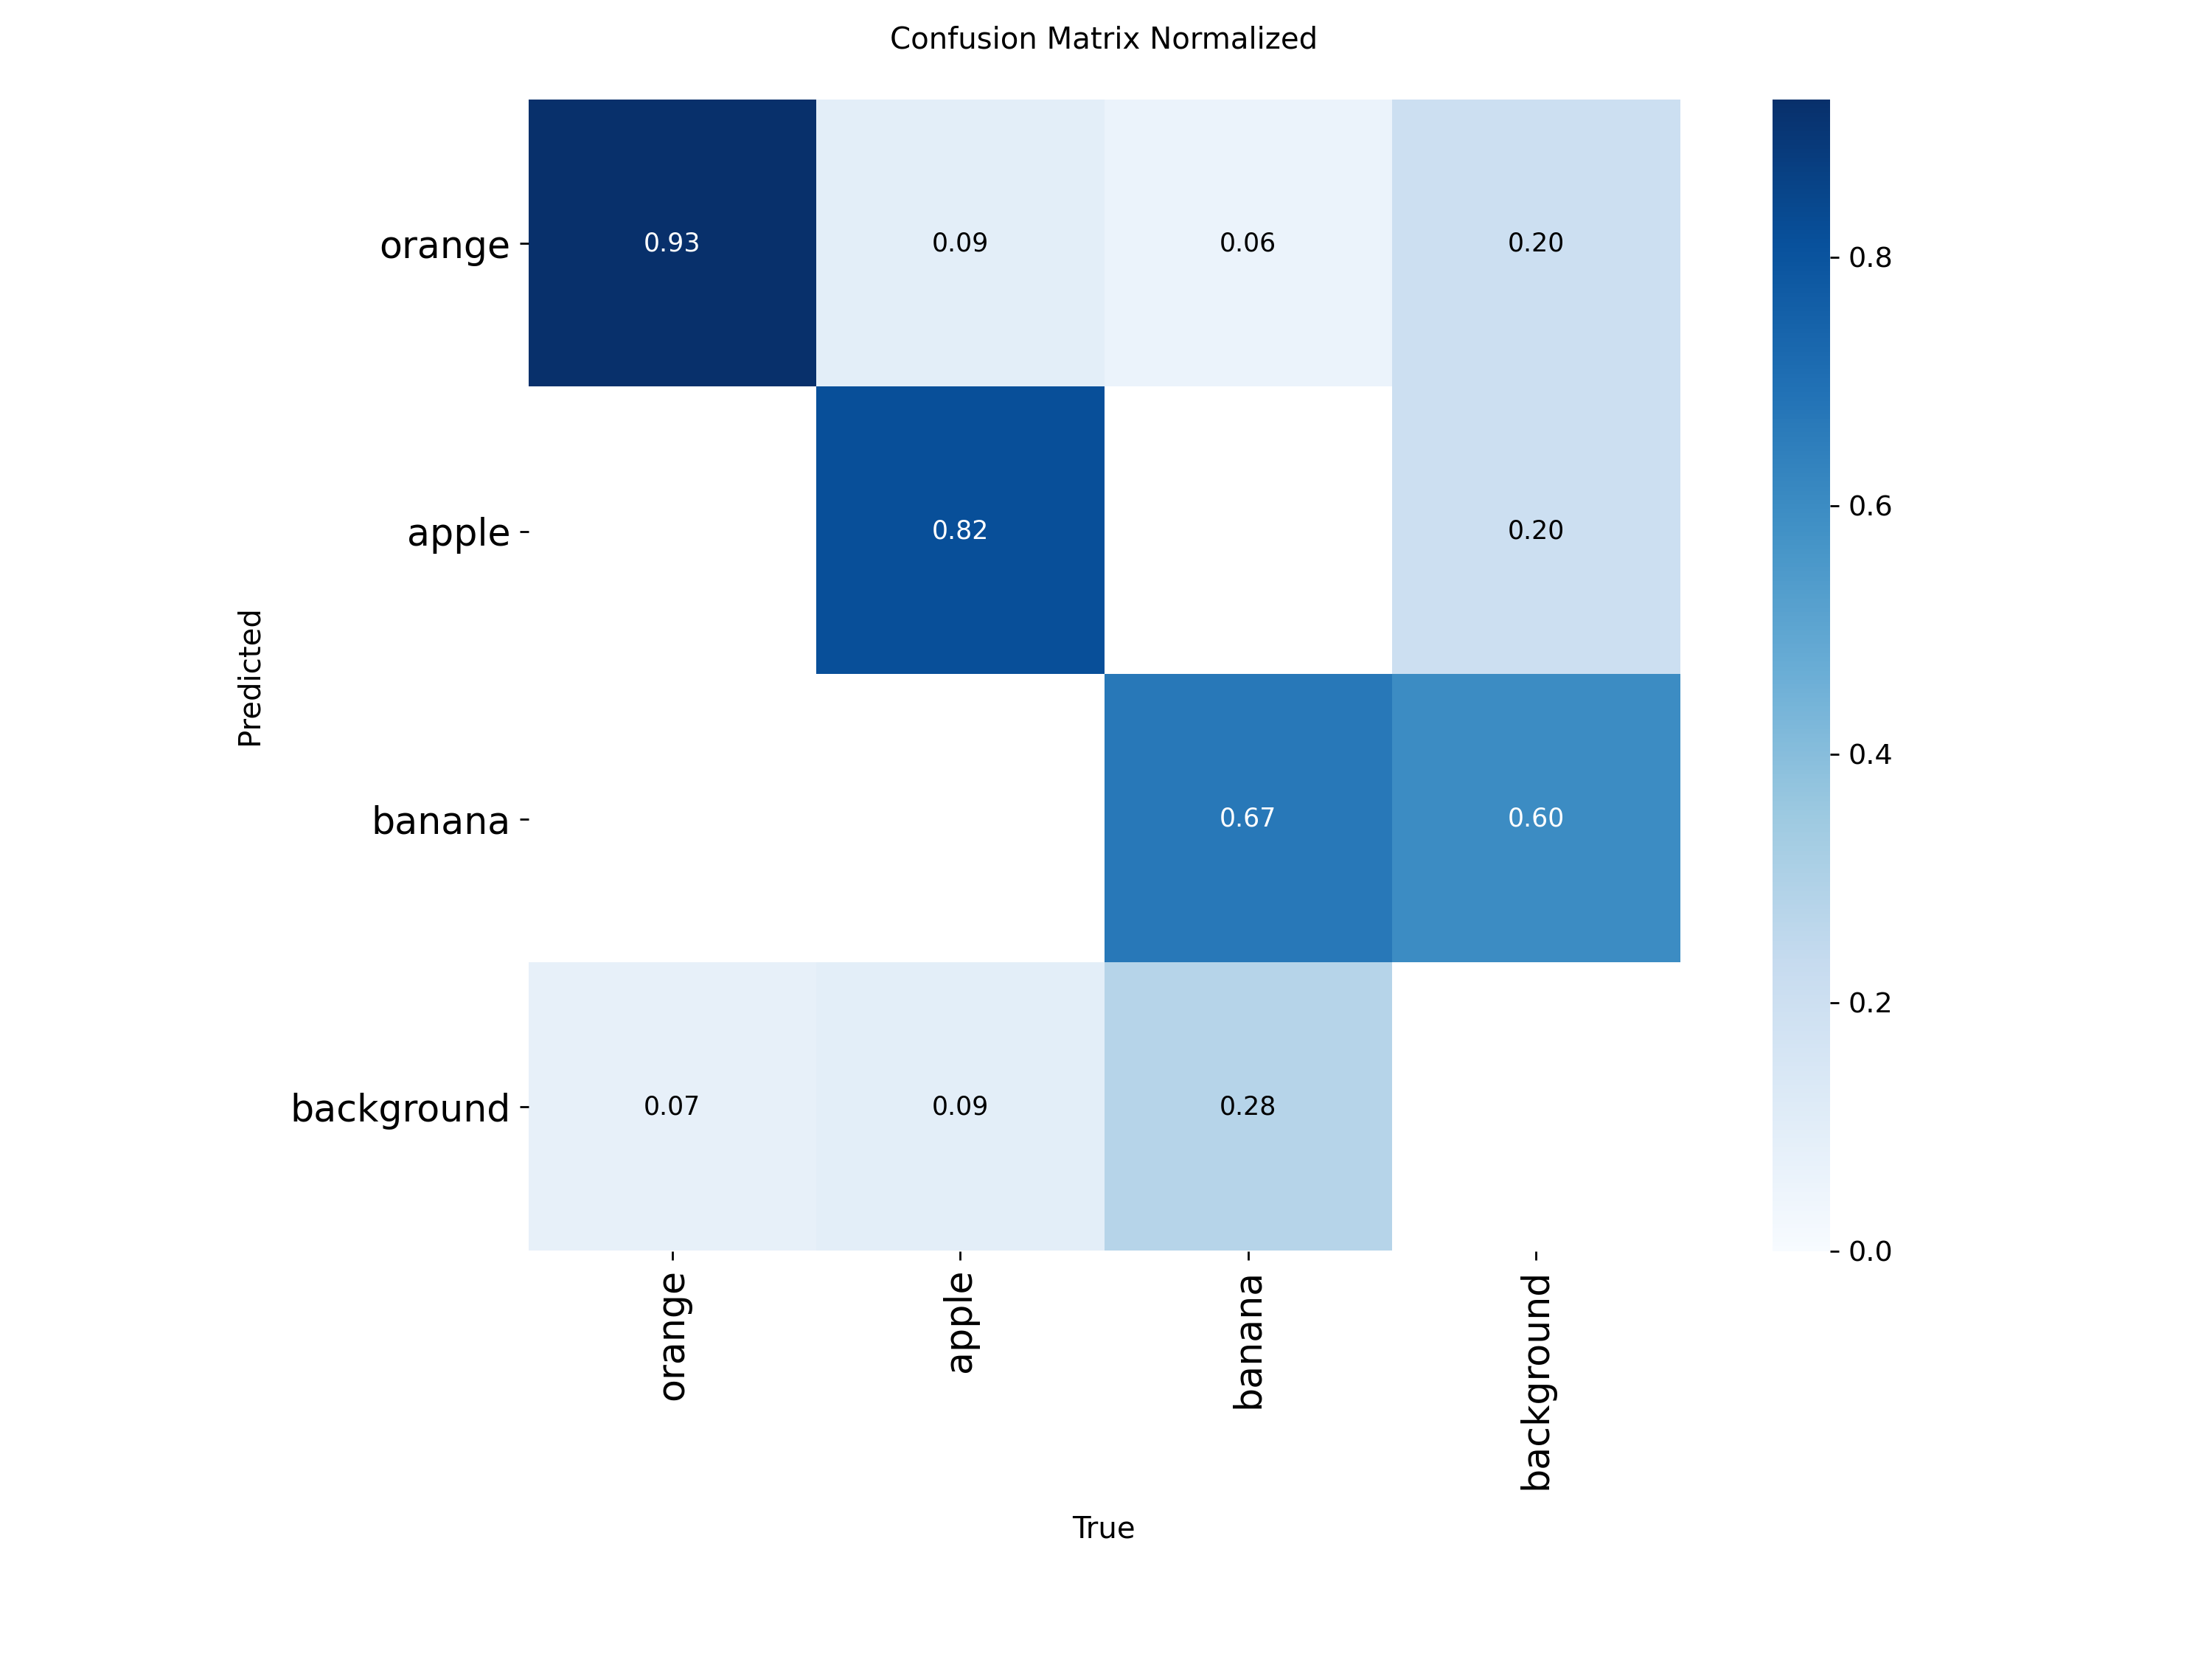

In [ ]:
%matplotlib inline
from PIL import Image

Image.open(f'{project_dir}/{run_name}/confusion_matrix_normalized.png')

**Local Confusion Matrix**



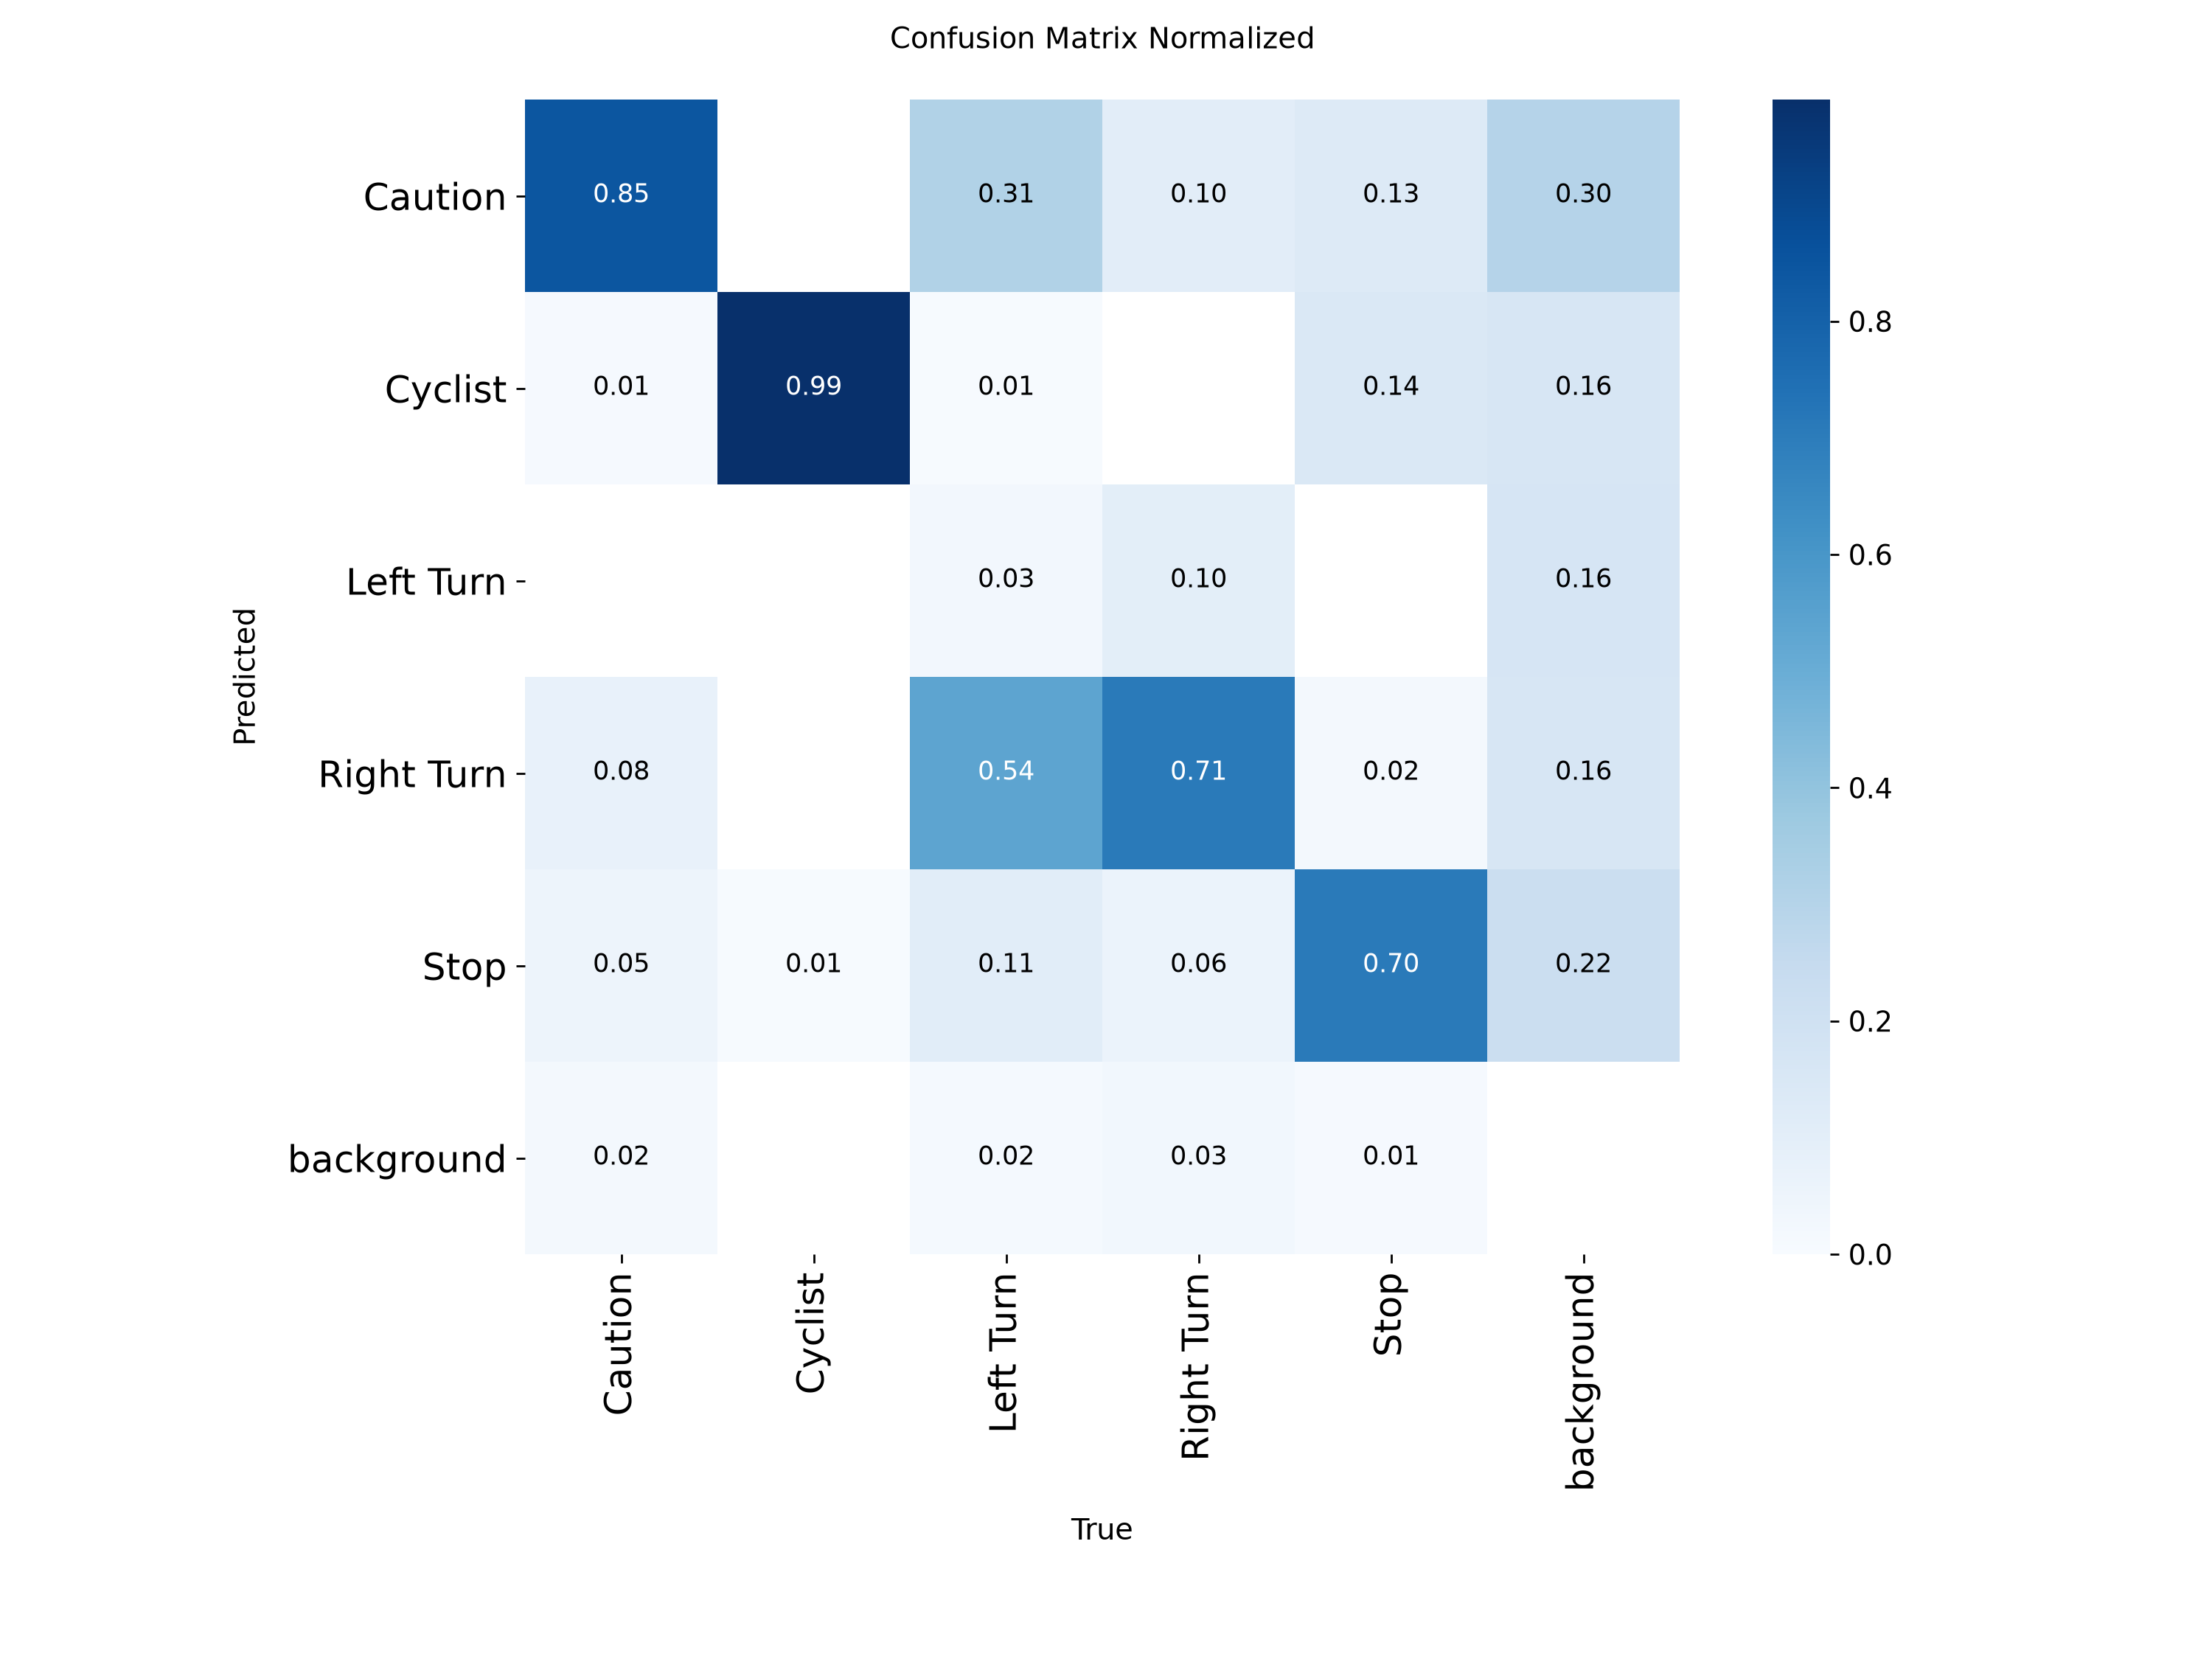

In [27]:
'''
%matplotlib inline
from PIL import Image

Image.open(f'{work_dir}/{run_name}/confusion_matrix_normalized.png')
'''

##Prediction

In [40]:
predict = 'predict'
model = YOLO(f'{project_dir}/{run_name}/weights/best.pt')  # load a custom model

# Predict with the model with any image from internet?
img = 'https://raw.githubusercontent.com/zhengyangsu/Computer-Vision-Project-Overview/main/misc/A-cyclist-riding.jpg'
results = model(img, save=True, project=work_dir)
print(results[0].save_dir)


Found https://raw.githubusercontent.com/zhengyangsu/Computer-Vision-Project-Overview/main/misc/A-cyclist-riding.jpg locally at A-cyclist-riding.jpg
image 1/1 G:\My Drive\Colab_Notebooks\A-cyclist-riding.jpg: 640x640 1 Cyclist, 63.7ms
Speed: 4.7ms preprocess, 63.7ms inference, 2.9ms postprocess per image at shape (1, 3, 640, 640)
Results saved to G:\My Drive\Colab_Notebooks\workbench\predict
G:\My Drive\Colab_Notebooks\workbench\predict


In [ ]:
'''
model = YOLO(f'{work_dir}/{run_name}/weights/best.pt')  # load a custom model

# Predict with the model with any image from internet?
img = 'https://raw.githubusercontent.com/zhengyangsu/Computer-Vision-Project-Overview/main/misc/A-cyclist-riding.jpg'
results = model(img, save=True, project=work_dir)
print(results[0].save_dir)
'''

In [ ]:
# SHOW THE IMAGE STORED
%matplotlib inline
from PIL import Image

Image.open(f'{project_dir}/{predict}/A-cyclist-riding.jpg')

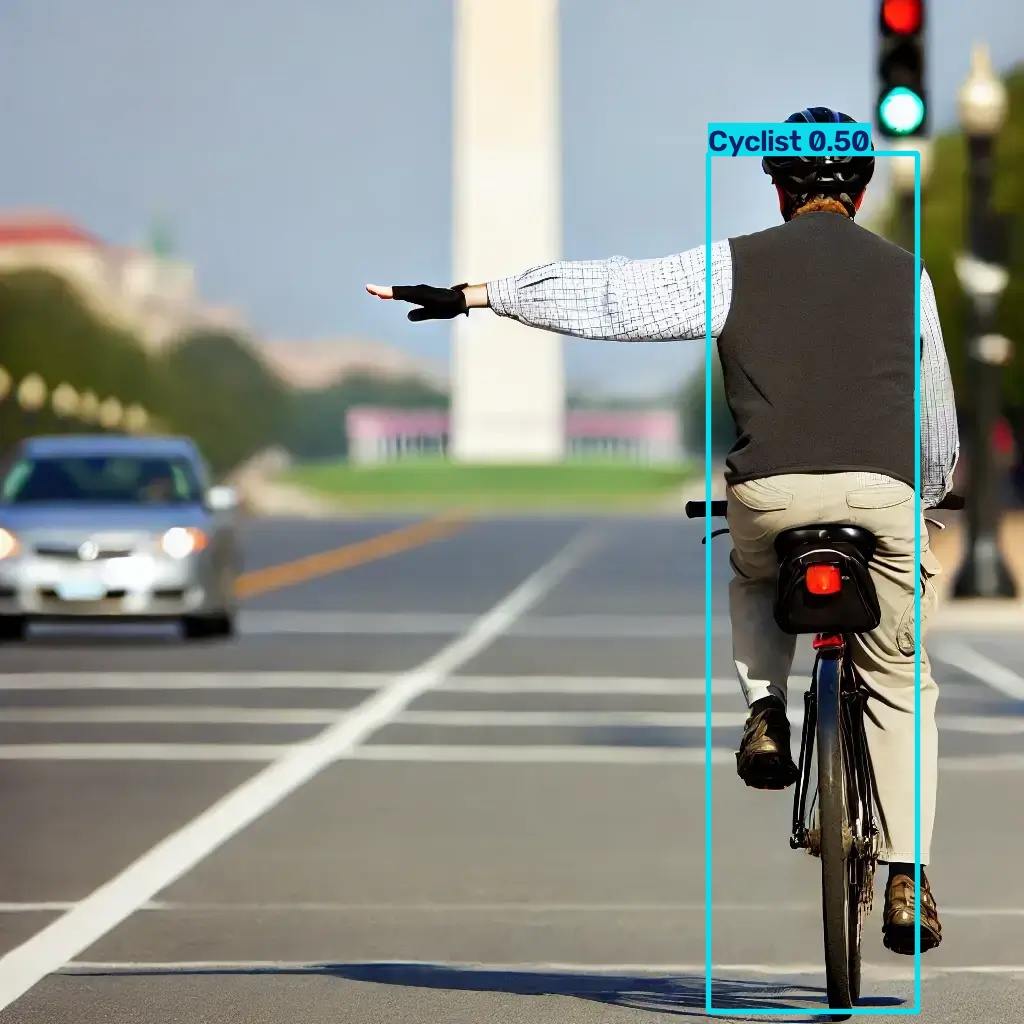

In [42]:
'''
# SHOW THE IMAGE STORED
%matplotlib inline
from PIL import Image

Image.open(f'{work_dir}/{predict}/A-cyclist-riding.jpg')
'''

# **Training curves**

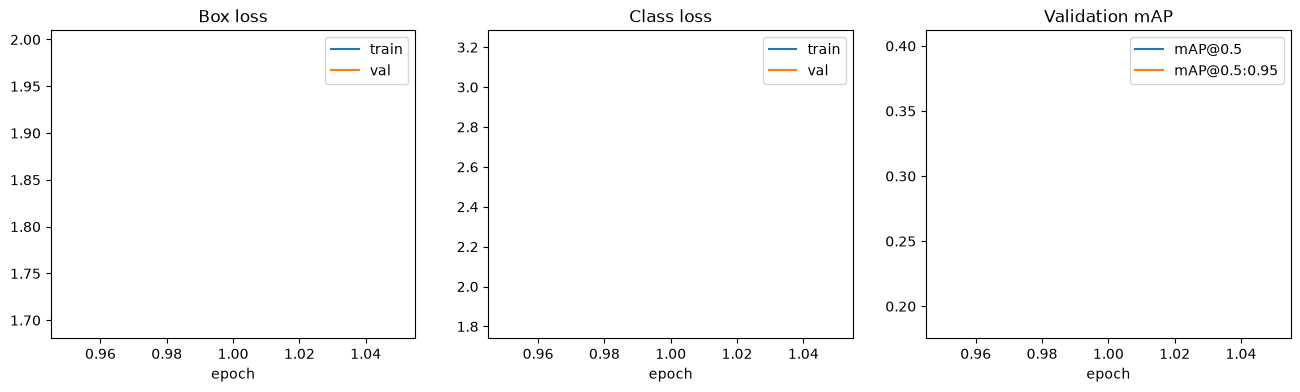

In [45]:
#If the validation loss flattens or rises while the training loss keeps falling, the model is overfitting.
#If mAP is still climbing at the last epoch, train longer.
run_dir = f'{project_dir}/{run_name}'        # the run folder (change to yours)
res = pd.read_csv(f'{run_dir}/results.csv')
res.columns = res.columns.str.strip()           # column names can have stray spaces

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].plot(res['epoch'], res['train/box_loss'], label='train')
ax[0].plot(res['epoch'], res['val/box_loss'], label='val')
ax[0].set_title('Box loss')

ax[1].plot(res['epoch'], res['train/cls_loss'], label='train')
ax[1].plot(res['epoch'], res['val/cls_loss'], label='val')
ax[1].set_title('Class loss')

ax[2].plot(res['epoch'], res['metrics/mAP50(B)'], label='mAP@0.5')
ax[2].plot(res['epoch'], res['metrics/mAP50-95(B)'], label='mAP@0.5:0.95')
ax[2].set_title('Validation mAP')

for a in ax:
    a.set_xlabel('epoch')
    a.legend()
plt.show()

# **Learning curve by training**

In [ ]:
#If the curve is still rising at 1.0, more data would improve the model.
#If it flattens, more data of the same kind won’t help much. You would need more variety instead.
'''
fractions = [0.1, 0.25, 0.5, 1.0]
scores = []

for frac in fractions:
    m = YOLO('yolov8n.pt')                       # fresh model every time
    m.train(data="config.yaml", epochs=10, imgsz=640, batch=16,
            fraction=frac, fliplr=0.0, seed=0,
            project=project_dir, name=f'lc_{int(frac*100)}', exist_ok=True)
    val = m.val(data="config.yaml", split="val")  # score on the same validation set
    scores.append(val.box.map50)
    print(f'fraction {frac}: mAP50 = {val.box.map50:.3f}')

plt.plot(fractions, scores, marker='o')
plt.xlabel('fraction of training data')
plt.ylabel('validation mAP@0.5')
plt.title('Learning curve')
plt.show()
'''